In [3]:

import os

print(os.listdir("/content"))


['.config', 'Unemployment_Rate_upto_11_2020.csv', 'sample_data']


In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [8]:
df = pd.read_csv("/content/Unemployment_Rate_upto_11_2020.csv")

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

print("First five rows:")
print(df.head())

print("\nDataset size:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())


First five rows:
           Region         Date Frequency  Estimated Unemployment Rate (%)  \
0  Andhra Pradesh   31-01-2020         M                             5.48   
1  Andhra Pradesh   29-02-2020         M                             5.83   
2  Andhra Pradesh   31-03-2020         M                             5.79   
3  Andhra Pradesh   30-04-2020         M                            20.51   
4  Andhra Pradesh   31-05-2020         M                            17.43   

   Estimated Employed  Estimated Labour Participation Rate (%) Region.1  \
0            16635535                                    41.02    South   
1            16545652                                    40.90    South   
2            15881197                                    39.18    South   
3            11336911                                    33.10    South   
4            12988845                                    36.46    South   

   longitude  latitude  
0    15.9129     79.74  
1    15.9129     79

In [9]:

print("Missing values before cleaning:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

df = df.drop_duplicates()

print("\nDataset size after removing duplicates:")
print(df.shape)


Missing values before cleaning:
Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Region.1                                   0
longitude                                  0
latitude                                   0
dtype: int64

Duplicate rows: 0

Dataset size after removing duplicates:
(267, 9)


In [10]:

df["Date"] = pd.to_datetime(
    df["Date"].astype(str).str.strip(),
    errors="coerce",
    dayfirst=True
)

df["Estimated Unemployment Rate (%)"] = pd.to_numeric(
    df["Estimated Unemployment Rate (%)"],
    errors="coerce"
)

df = df.dropna(
    subset=["Date", "Estimated Unemployment Rate (%)"]
)

print(df[[
    "Date",
    "Estimated Unemployment Rate (%)"
]].head())

print("Cleaned dataset size:", df.shape)


        Date  Estimated Unemployment Rate (%)
0 2020-01-31                             5.48
1 2020-02-29                             5.83
2 2020-03-31                             5.79
3 2020-04-30                            20.51
4 2020-05-31                            17.43
Cleaned dataset size: (267, 9)


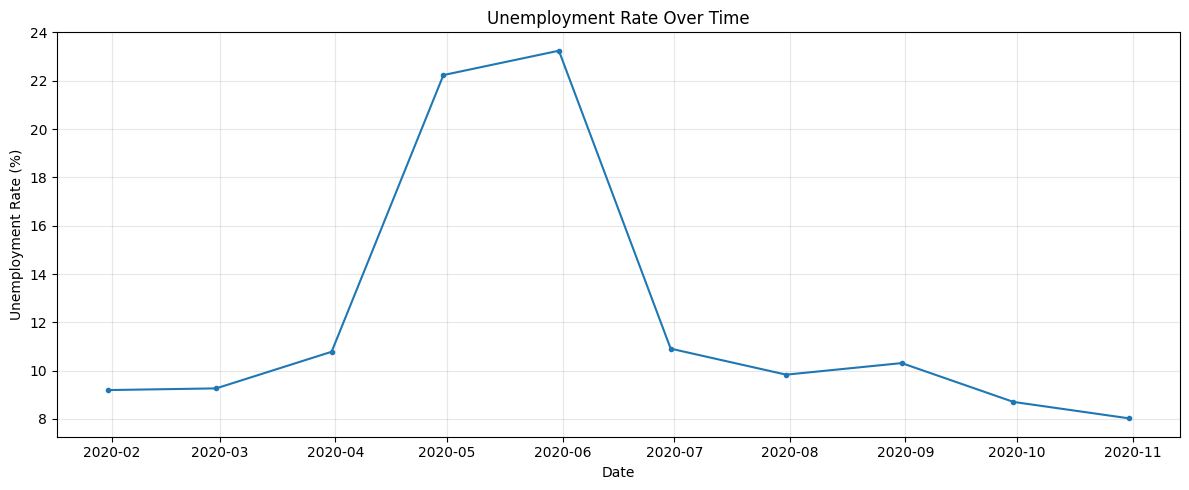

In [11]:

trend = (
    df.groupby("Date")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_index()
)

plt.figure(figsize=(12, 5))
plt.plot(trend.index, trend.values, marker="o", markersize=3)

plt.title("Unemployment Rate Over Time")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [12]:

pre_covid = trend[
    (trend.index >= "2019-01-01") &
    (trend.index < "2020-03-01")
]

during_covid = trend[
    (trend.index >= "2020-03-01") &
    (trend.index < "2022-01-01")
]

print("Average before COVID-19:",
      round(pre_covid.mean(), 2), "%")

print("Average during COVID-19:",
      round(during_covid.mean(), 2), "%")

if pre_covid.empty or during_covid.empty:
    print("Warning: The dataset does not cover both periods.")
elif during_covid.mean() > pre_covid.mean():
    print("The average rate was higher during the selected COVID period.")
else:
    print("The average rate was not higher during the selected COVID period.")


Average before COVID-19: 9.23 %
Average during COVID-19: 13.01 %
The average rate was higher during the selected COVID period.


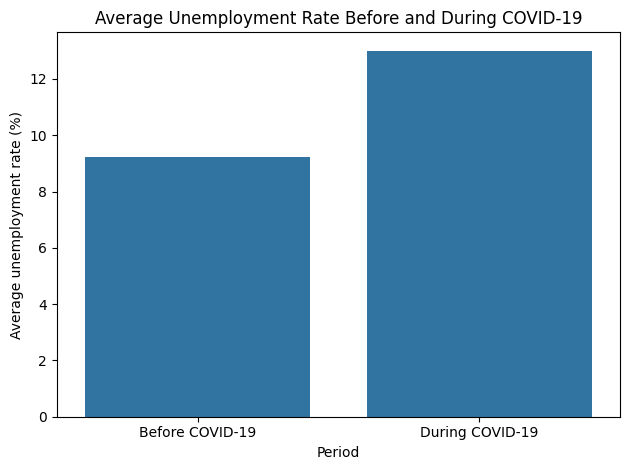

In [13]:

comparison = pd.DataFrame({
    "Period": ["Before COVID-19", "During COVID-19"],
    "Average rate": [
        pre_covid.mean(),
        during_covid.mean()
    ]
}).dropna()

sns.barplot(
    data=comparison,
    x="Period",
    y="Average rate"
)

plt.title("Average Unemployment Rate Before and During COVID-19")
plt.xlabel("Period")
plt.ylabel("Average unemployment rate (%)")
plt.tight_layout()
plt.show()


Region
Haryana             27.477000
Tripura             25.055000
Jharkhand           19.539000
Bihar               19.471000
Delhi               18.414000
Puducherry          17.942000
Jammu & Kashmir     16.477778
Himachal Pradesh    16.065000
Rajasthan           15.868000
Tamil Nadu          12.187000
Goa                 12.167000
Punjab              11.981000
Uttarakhand         11.156000
West Bengal         10.192000
Sikkim               9.792500
Uttar Pradesh        9.737000
Kerala               9.434000
Andhra Pradesh       8.664000
Maharashtra          7.979000
Chhattisgarh         7.819000
Karnataka            7.668000
Madhya Pradesh       6.854000
Telangana            6.833000
Odisha               6.462000
Gujarat              6.376000
Assam                4.856000
Meghalaya            3.866000
Name: Estimated Unemployment Rate (%), dtype: float64


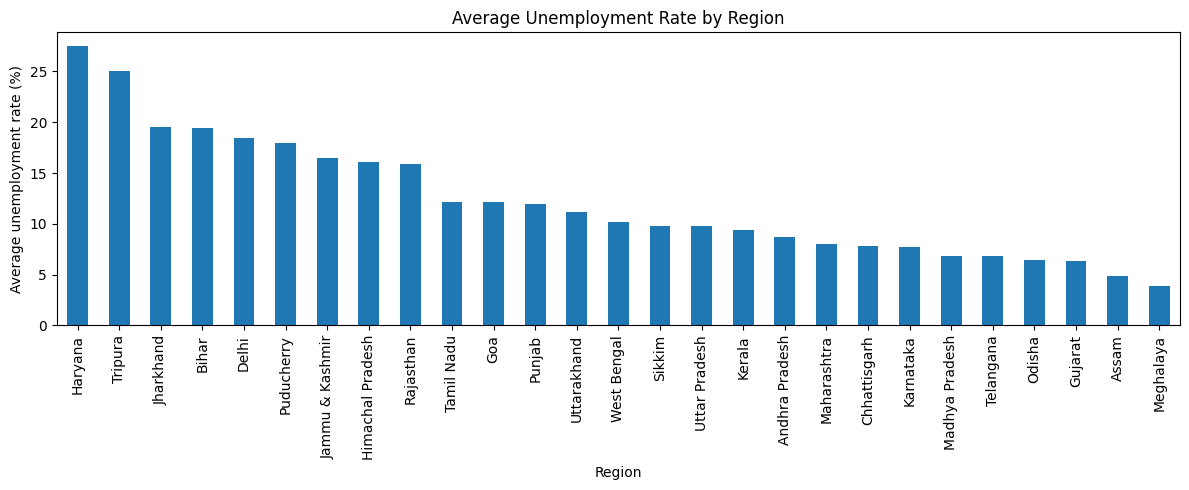

In [14]:

if "Region" in df.columns:
    region_rates = (
        df.groupby("Region")[
            "Estimated Unemployment Rate (%)"
        ]
        .mean()
        .sort_values(ascending=False)
    )

    print(region_rates)

    region_rates.plot(
        kind="bar",
        figsize=(12, 5),
        title="Average Unemployment Rate by Region"
    )

    plt.ylabel("Average unemployment rate (%)")
    plt.tight_layout()
    plt.show()
else:
    print("No Region column found in this dataset.")
